## Setup — Ejecutar primero

In [ ]:
# ── Instalación de dependencias ─────────
# yfinance no viene preinstalado en Colab
!pip install yfinance --quiet

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings('ignore')

# Estadística e inferencia
from scipy import stats
from scipy.stats import norm
from statsmodels.stats.stattools import jarque_bera

# Regresión y diagnósticos
import statsmodels.api as sm
from statsmodels.stats.diagnostic import (
    het_breuschpagan,
    acorr_ljungbox,
    linear_reset,
)
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.nonparametric.smoothers_lowess import lowess

# Métricas de predicción
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import yfinance as yf

plt.style.use('seaborn-v0_8-whitegrid')
print("✅ Librerías cargadas correctamente.")


✅ Librerías cargadas correctamente.


In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# CONFIGURACIÓN — Modifica estos parámetros para cambiar el caso de estudio
# ══════════════════════════════════════════════════════════════════════════════

TICKER_ACTIVO   = 'GOOG'         # Activo a analizar (cualquier ticker de Yahoo Finance)
TICKER_MERCADO  = 'SPY'         # Proxy del mercado
TICKER_RF       = '^IRX'        # Tasa libre de riesgo (T-Bill 13 semanas)

FECHA_INICIO    = '2023-01-01'
FECHA_FIN       = '2026-08-13'

NIVEL_CONFIANZA = 0.95          # Para IC, VaR e intervalos de predicción
ALPHA_STAT      = 0.05          # Nivel de significancia para pruebas de hipótesis
N_BOOTSTRAP     = 5000          # Iteraciones Bootstrap (reducir a 1000 si es lento)
PROPORCION_TRAIN= 0.80          # % datos para entrenamiento
DIAS_ANIO       = 252           # Días hábiles para anualizar

COLORES = {
    'activo':    '#2E4057',
    'mercado':   '#E84855',
    'neutro':    '#A9A9A9',
    'positivo':  '#3BB273',
    'negativo':  '#E84855',
    'var':       '#FF6B35',
    'intervalo': '#6A8EAE',
}

print(f"Configuración: {TICKER_ACTIVO} vs {TICKER_MERCADO} | {FECHA_INICIO} → {FECHA_FIN}")
print(f"Train/Test: {int(PROPORCION_TRAIN*100)}% / {int((1-PROPORCION_TRAIN)*100)}%  |  Bootstrap: {N_BOOTSTRAP:,} iter")


Configuración: GOOG vs SPY | 2023-01-01 → 2026-08-13
Train/Test: 80% / 19%  |  Bootstrap: 5,000 iter


## Carga de Datos

In [ ]:
# ── Descarga de precios de Yahoo Finance ───────────────────────────────────────
print("Descargando datos...")
raw = yf.download(
    [TICKER_ACTIVO, TICKER_MERCADO, TICKER_RF],
    start=FECHA_INICIO, end=FECHA_FIN,
    auto_adjust=True, progress=False
)['Close']
raw.columns = ['activo', 'mercado', 'rf_anual']

# Tasa libre de riesgo: de % anual a tasa diaria efectiva
# r_d = (1 + r_a/100)^(1/252) - 1
raw['rf_diaria'] = (1 + raw['rf_anual'] / 100) ** (1 / 252) - 1

# ── Retornos logarítmicos ──────────────────────────────────────────────────────
# r_t = ln(P_t / P_{t-1})
# Ventajas: aditividad temporal, simetría, mejor comportamiento estadístico
retornos = pd.DataFrame(index=raw.index)
retornos['activo']  = np.log(raw['activo']  / raw['activo'].shift(1))
retornos['mercado'] = np.log(raw['mercado'] / raw['mercado'].shift(1))
retornos['rf']      = raw['rf_diaria']

# Exceso de retorno = retorno bruto − tasa libre de riesgo
# Esta es la variable central del CAPM: (r_i - r_f) = α + β(r_m - r_f) + ε
retornos['exceso_activo']  = retornos['activo']  - retornos['rf']
retornos['exceso_mercado'] = retornos['mercado'] - retornos['rf']
retornos = retornos.dropna()

# ── División train / test (CRONOLÓGICA — nunca aleatoria en series financieras) ─
# El modelo solo puede ver el pasado; el test simula predicción futura real
n_total = len(retornos)
n_train = int(n_total * PROPORCION_TRAIN)
train = retornos.iloc[:n_train].copy()
test  = retornos.iloc[n_train:].copy()

print(f" Datos listos: {n_total} observaciones")
print(f" Train: {len(train)} obs  [{train.index[0].date()} → {train.index[-1].date()}]")
print(f" Test:  {len(test)} obs   [{test.index[0].date()} → {test.index[-1].date()}]")
retornos.head(3)


Descargando datos...
 Datos listos: 904 observaciones
 Train: 723 obs  [2023-01-04 → 2025-11-19]
 Test:  181 obs   [2025-11-20 → 2026-08-12]


,activo,mercado,rf,exceso_activo,exceso_mercado
Date,,,,,
2023-01-04,-0.011098,0.007690,0.000171,-0.011269,0.007520
2023-01-05,-0.022112,-0.011479,0.000175,-0.022286,-0.011654
2023-01-06,0.015892,0.022673,0.000174,0.015718,0.022499


---
## Sesión 1 — Estadística Inferencial

**Conceptos:** Retornos logarítmicos · Parámetros vs. estimadores · SEM · IC · VaR · Kurtosis


In [ ]:
# ── Función de estadísticas inferenciales ──────────────────────────────────────
def analizar_retornos(serie, nombre):
    """
    Calcula las estadísticas inferenciales completas para una serie de retornos.

    Diferencia clave IC vs VaR:
      IC = x̄ ± Z × (s/√n)  → usa SEM, mide incertidumbre sobre la MEDIA μ
      VaR = x̄ - Z × s      → usa s directamente, mide riesgo de UN día individual

    Corrección de Bessel: usamos n−1 en s² para corregir el sesgo del estimador.
    """
    n      = len(serie)
    media  = serie.mean()
    vol    = serie.std()           # ddof=1 por defecto (corrección de Bessel)
    sem    = vol / np.sqrt(n)      # Error estándar: precisión de la estimación de μ
    z_crit = norm.ppf(1 - (1 - NIVEL_CONFIANZA) / 2)

    ic_inf      = media - z_crit * sem
    ic_sup      = media + z_crit * sem
    var_param   = media - z_crit * vol   # VaR paramétrico (asume normalidad)
    var_hist    = serie.quantile(1 - NIVEL_CONFIANZA)  # VaR histórico (empírico)
    vol_anual   = vol   * np.sqrt(DIAS_ANIO)
    media_anual = media * DIAS_ANIO
    sharpe      = media_anual / vol_anual

    print(f"\n{'═'*55}")
    print(f"  {nombre} — Estadísticas Inferenciales")
    print(f"{'═'*55}")
    print(f"  n = {n} | Media diaria: {media:.5%} | Vol diaria: {vol:.5%}")
    print(f"  SEM: {sem:.7%}  (cuán precisa es la estimación de μ)")
    print(f"  IC {int(NIVEL_CONFIANZA*100)}% media: [{ic_inf:.5%}, {ic_sup:.5%}]")
    print(f"  ── Anualizado ──")
    print(f"  Media anual: {media_anual:.2%}  |  Vol anual: {vol_anual:.2%}  |  Sharpe: {sharpe:.4f}")
    print(f"  ── VaR diario ──")
    print(f"  VaR {int(NIVEL_CONFIANZA*100)}% paramétrico: {var_param:.4%}  (asume normalidad)")
    print(f"  VaR {int(NIVEL_CONFIANZA*100)}% histórico:   {var_hist:.4%}  (empírico, sin supuesto)")
    print(f"  Asimetría: {serie.skew():.4f}  |  Curtosis excedente: {serie.kurtosis():.4f}  (Normal=0)")

    if serie.kurtosis() > 1:
        dif = abs(var_hist - var_param) / abs(var_param) * 100
        print(f"    Curtosis excesiva: VaR paramétrico y histórico difieren {dif:.1f}%.")
        print(f"      El VaR paramétrico SUBESTIMA el riesgo real.")
    if ic_inf < 0 < ic_sup:
        print(f"    El 0 está en el IC → retorno no significativo estadísticamente.")
    else:
        print(f"    IC no contiene 0 → retorno estadísticamente significativo.")

    return dict(media=media, vol=vol, sem=sem, ic=(ic_inf,ic_sup),
                var_param=var_param, var_hist=var_hist,
                media_anual=media_anual, vol_anual=vol_anual, sharpe=sharpe)

s1_activo  = analizar_retornos(retornos['activo'],  TICKER_ACTIVO)
s1_mercado = analizar_retornos(retornos['mercado'], TICKER_MERCADO)



═══════════════════════════════════════════════════════
  GOOG — Estadísticas Inferenciales
═══════════════════════════════════════════════════════
  n = 904 | Media diaria: 0.14914% | Vol diaria: 1.93116%
  SEM: 0.0642293%  (cuán precisa es la estimación de μ)
  IC 95% media: [0.02325%, 0.27502%]
  ── Anualizado ──
  Media anual: 37.58%  |  Vol anual: 30.66%  |  Sharpe: 1.2259
  ── VaR diario ──
  VaR 95% paramétrico: -3.6359%  (asume normalidad)
  VaR 95% histórico:   -2.7445%  (empírico, sin supuesto)
  Asimetría: 0.0406  |  Curtosis excedente: 3.9583  (Normal=0)
    Curtosis excesiva: VaR paramétrico y histórico difieren 24.5%.
      El VaR paramétrico SUBESTIMA el riesgo real.
    IC no contiene 0 → retorno estadísticamente significativo.

═══════════════════════════════════════════════════════
  SPY — Estadísticas Inferenciales
═══════════════════════════════════════════════════════
  n = 904 | Media diaria: 0.08320% | Vol diaria: 0.94747%
  SEM: 0.0315125%  (cuán precisa es la 

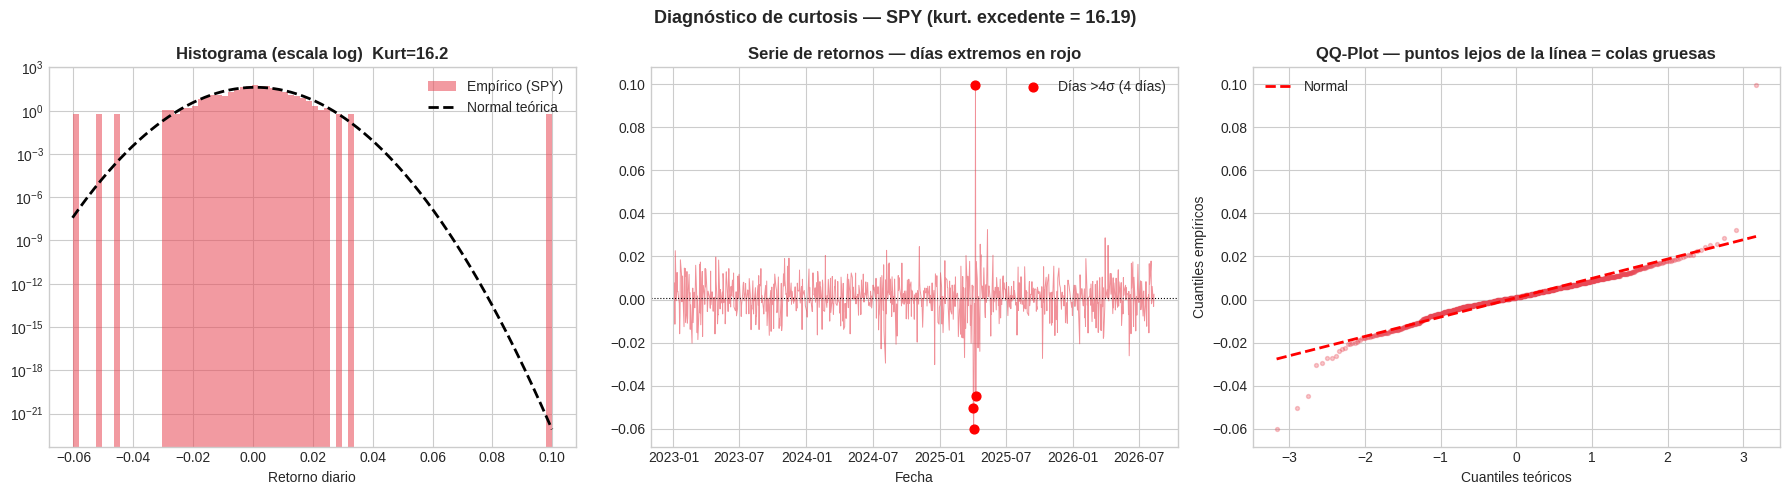


LOS 4 DÍAS MÁS EXTREMOS DE SPY
═══════════════════════════════════════════════════════
  2025-04-09:  +9.986%   (+10.5σ)
  2025-04-04:  -6.033%   (-6.5σ)
  2025-04-03:  -5.054%   (-5.4σ)
  2025-04-10:  -4.481%   (-4.8σ)
  2025-05-12:  +3.251%   (+3.3σ)
  2024-12-18:  -3.026%   (-3.3σ)
  2024-08-05:  -2.956%   (-3.2σ)
  2026-03-31:  +2.865%   (+2.9σ)
  2025-10-10:  -2.740%   (-3.0σ)
  2025-03-10:  -2.700%   (-2.9σ)


In [ ]:
# ══════════════════════════════════════════════════════════════════
# DIAGNÓSTICO DE CURTOSIS — ¿qué días están inflando el número?
# Pegar después de correr analizar_retornos() para SPY
# ══════════════════════════════════════════════════════════════════

r = retornos['mercado']  # retornos de SPY
media, vol = r.mean(), r.std()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ── 1. Histograma vs Normal (ya lo tiene, pero con zoom en colas) ──
ax = axes[0]
x = np.linspace(r.min(), r.max(), 400)
ax.hist(r, bins=80, density=True, color=COLORES['mercado'], alpha=0.55, label='Empírico (SPY)')
ax.plot(x, norm.pdf(x, media, vol), color='black', lw=2, ls='--', label='Normal teórica')
ax.set_yscale('log')  # ESCALA LOG: aquí se ve la diferencia en las colas
ax.set_title(f'Histograma (escala log)  Kurt={r.kurtosis():.1f}', fontweight='bold')
ax.set_xlabel('Retorno diario'); ax.legend()

# ── 2. Serie de tiempo con los días extremos marcados ───────────────
ax = axes[1]
umbral = 4 * vol  # días a más de 4 desviaciones estándar = "extremos"
extremos = r[np.abs(r - media) > umbral]
ax.plot(r.index, r.values, color=COLORES['mercado'], lw=0.7, alpha=0.6)
ax.scatter(extremos.index, extremos.values, color='red', s=40, zorder=5,
           label=f'Días >4σ ({len(extremos)} días)')
ax.axhline(media, color='black', lw=0.8, ls=':')
ax.set_title('Serie de retornos — días extremos en rojo', fontweight='bold')
ax.legend(); ax.set_xlabel('Fecha')

# ── 3. QQ-plot con foco en colas ─────────────────────────────────────
ax = axes[2]
(osm, osr), (slope, intercept, _) = stats.probplot(r, dist='norm')
ax.scatter(osm, osr, alpha=0.3, s=8, color=COLORES['mercado'])
ax.plot(osm, slope*np.array(osm)+intercept, color='red', lw=2, ls='--', label='Normal')
ax.set_title('QQ-Plot — puntos lejos de la línea = colas gruesas', fontweight='bold')
ax.set_xlabel('Cuantiles teóricos'); ax.set_ylabel('Cuantiles empíricos'); ax.legend()

plt.suptitle(f'Diagnóstico de curtosis — {TICKER_MERCADO} (kurt. excedente = {r.kurtosis():.2f})',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('diagnostico_curtosis_spy.png', dpi=130, bbox_inches='tight')
plt.show()

# ── Tabla: los días más extremos (los "culpables" de la curtosis) ───
print(f"\nLOS {min(10,len(extremos))} DÍAS MÁS EXTREMOS DE {TICKER_MERCADO}")
print("═"*55)
tabla_extremos = r.reindex(r.abs().sort_values(ascending=False).index[:10])
for fecha, ret in tabla_extremos.items():
    sigma = (ret - media) / vol
    print(f"  {fecha.date()}:  {ret:+.3%}   ({sigma:+.1f}σ)")

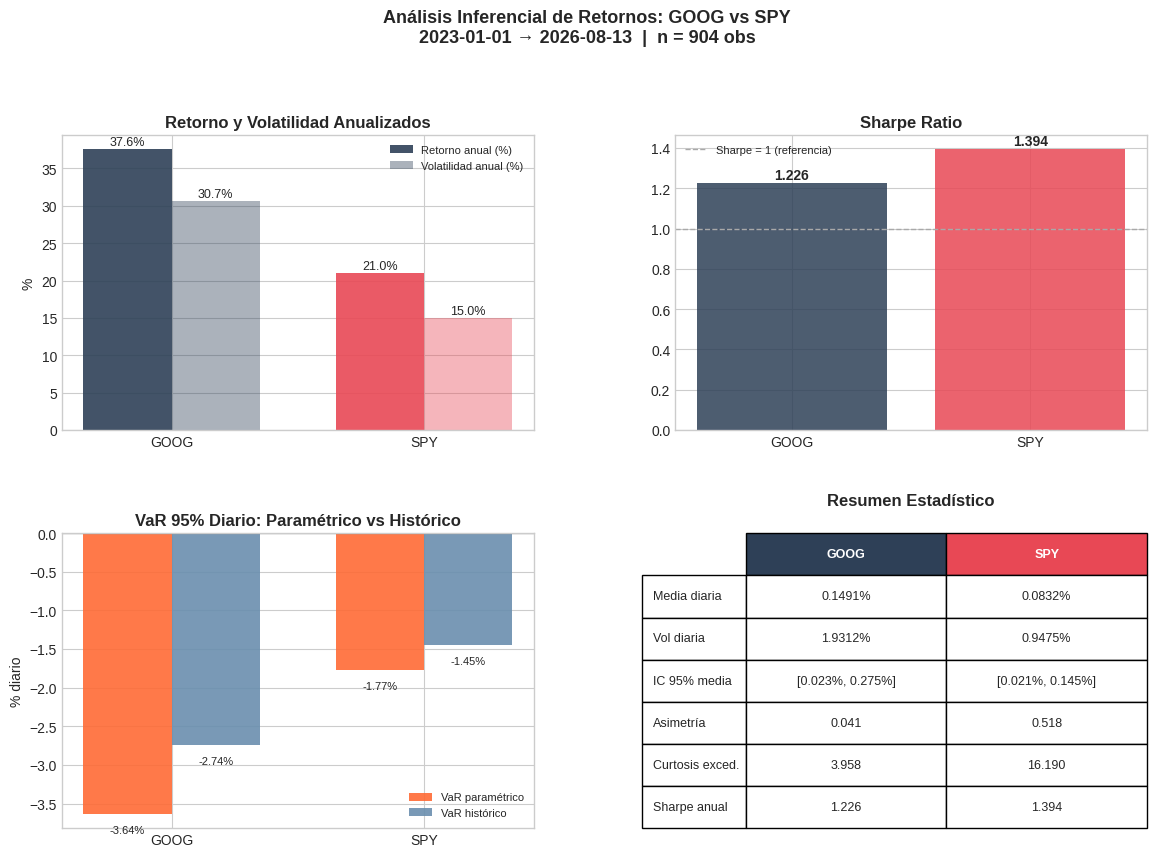

In [ ]:
# ── Gráfico resumen para informe: GOOG vs SPY ──────────────────────────────
fig = plt.figure(figsize=(14, 9))
gs = gridspec.GridSpec(2, 2, height_ratios=[1, 1], hspace=0.35, wspace=0.3)

nombres = [TICKER_ACTIVO, TICKER_MERCADO]
stats_list = [s1_activo, s1_mercado]
colores_barra = [COLORES['activo'], COLORES['mercado']]

# ── Panel 1: Media y Volatilidad anualizada ────────────────────────────────
ax1 = fig.add_subplot(gs[0, 0])
x = np.arange(2)
width = 0.35
medias = [s['media_anual']*100 for s in stats_list]
vols   = [s['vol_anual']*100 for s in stats_list]
ax1.bar(x - width/2, medias, width, label='Retorno anual (%)', color=colores_barra, alpha=0.9)
ax1.bar(x + width/2, vols, width, label='Volatilidad anual (%)', color=colores_barra, alpha=0.4)
ax1.set_xticks(x); ax1.set_xticklabels(nombres)
ax1.set_ylabel('%')
ax1.set_title('Retorno y Volatilidad Anualizados', fontweight='bold')
ax1.legend(fontsize=8)
for i, (m, v) in enumerate(zip(medias, vols)):
    ax1.text(i - width/2, m + 0.5, f'{m:.1f}%', ha='center', fontsize=9)
    ax1.text(i + width/2, v + 0.5, f'{v:.1f}%', ha='center', fontsize=9)

# ── Panel 2: Sharpe Ratio ───────────────────────────────────────────────────
ax2 = fig.add_subplot(gs[0, 1])
sharpes = [s['sharpe'] for s in stats_list]
bars = ax2.bar(nombres, sharpes, color=colores_barra, alpha=0.85)
ax2.set_title('Sharpe Ratio', fontweight='bold')
ax2.axhline(1.0, color=COLORES['neutro'], linestyle='--', linewidth=1, label='Sharpe = 1 (referencia)')
ax2.legend(fontsize=8)
for b, s in zip(bars, sharpes):
    ax2.text(b.get_x()+b.get_width()/2, s + 0.02, f'{s:.3f}', ha='center', fontweight='bold')

# ── Panel 3: VaR paramétrico vs histórico ───────────────────────────────────
ax3 = fig.add_subplot(gs[1, 0])
x2 = np.arange(2)
var_param = [s['var_param']*100 for s in stats_list]
var_hist  = [s['var_hist']*100 for s in stats_list]
ax3.bar(x2 - width/2, var_param, width, label='VaR paramétrico', color=COLORES['var'], alpha=0.9)
ax3.bar(x2 + width/2, var_hist, width, label='VaR histórico', color=COLORES['intervalo'], alpha=0.9)
ax3.set_xticks(x2); ax3.set_xticklabels(nombres)
ax3.set_ylabel('% diario')
ax3.set_title(f'VaR {int(NIVEL_CONFIANZA*100)}% Diario: Paramétrico vs Histórico', fontweight='bold')
ax3.axhline(0, color='black', linewidth=0.8)
ax3.legend(fontsize=8)
for i, (p, h) in enumerate(zip(var_param, var_hist)):
    ax3.text(i - width/2, p - 0.25, f'{p:.2f}%', ha='center', fontsize=8)
    ax3.text(i + width/2, h - 0.25, f'{h:.2f}%', ha='center', fontsize=8)

# ── Panel 4: Tabla resumen (asimetría, curtosis, IC) ────────────────────────
ax4 = fig.add_subplot(gs[1, 1])
ax4.axis('off')
filas = ['Media diaria', 'Vol diaria', 'IC 95% media',
         'Asimetría', 'Curtosis exced.', 'Sharpe anual']
tabla_datos = []
for s in stats_list:
    tabla_datos.append([
        f"{s['media']:.4%}",
        f"{s['vol']:.4%}",
        f"[{s['ic'][0]:.3%}, {s['ic'][1]:.3%}]",
        f"{retornos['activo'].skew():.3f}" if s is s1_activo else f"{retornos['mercado'].skew():.3f}",
        f"{retornos['activo'].kurtosis():.3f}" if s is s1_activo else f"{retornos['mercado'].kurtosis():.3f}",
        f"{s['sharpe']:.3f}",
    ])
tabla = np.array(tabla_datos).T
tab = ax4.table(cellText=tabla, rowLabels=filas, colLabels=nombres,
                 cellLoc='center', loc='center', bbox=[0.15, 0, 0.85, 1])
tab.auto_set_font_size(False); tab.set_fontsize(9)
tab.scale(1, 1.8)
for j, nombre in enumerate(nombres):
    tab[0, j].set_facecolor(colores_barra[j])
    tab[0, j].set_text_props(color='white', fontweight='bold')
ax4.set_title('Resumen Estadístico', fontweight='bold', pad=20)

fig.suptitle(f'Análisis Inferencial de Retornos: {TICKER_ACTIVO} vs {TICKER_MERCADO}\n'
             f'{FECHA_INICIO} → {FECHA_FIN}  |  n = {len(retornos)} obs',
             fontsize=13, fontweight='bold', y=1.02)

plt.tight_layout()
plt.savefig('resumen_estadistico.png', dpi=150, bbox_inches='tight')
plt.show()

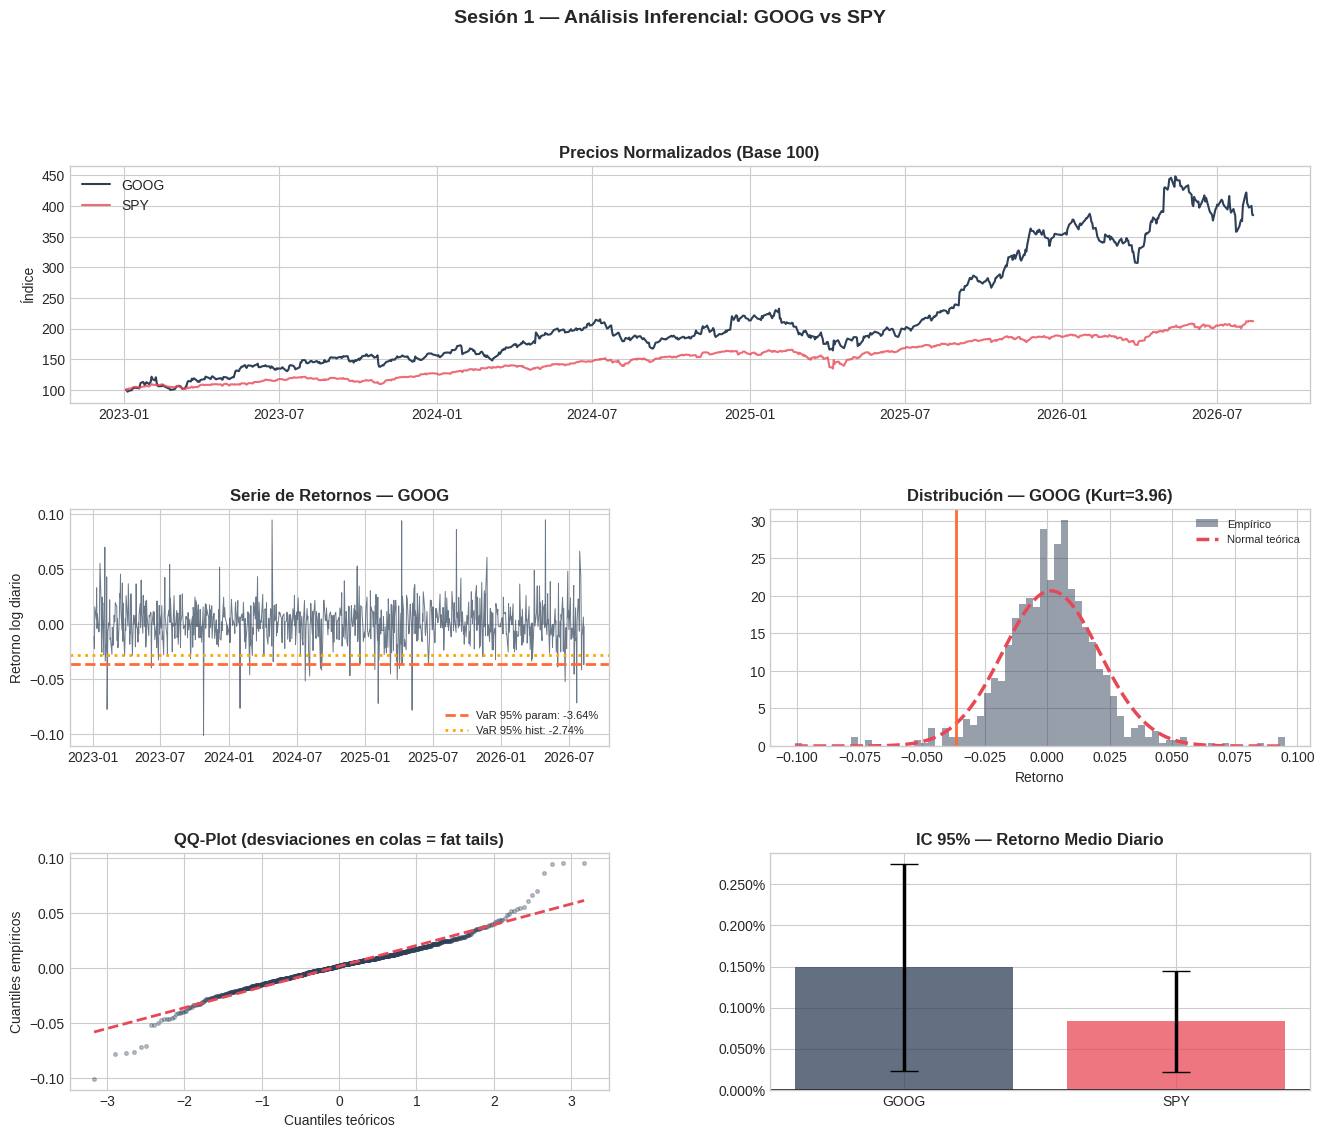

In [ ]:
# ── Visualización Sesión 1 ─────────────────────────────────────────────────────
raw_p = yf.download([TICKER_ACTIVO, TICKER_MERCADO], start=FECHA_INICIO,
                     end=FECHA_FIN, auto_adjust=True, progress=False)['Close']
raw_p.columns = ['activo','mercado']

fig = plt.figure(figsize=(16, 12))
gs  = gridspec.GridSpec(3, 2, hspace=0.45, wspace=0.3)

# Precios normalizados
ax = fig.add_subplot(gs[0, :])
pn = raw_p.dropna() / raw_p.dropna().iloc[0] * 100
ax.plot(pn['activo'],  color=COLORES['activo'],  lw=1.5, label=TICKER_ACTIVO)
ax.plot(pn['mercado'], color=COLORES['mercado'], lw=1.5, alpha=0.8, label=TICKER_MERCADO)
ax.set_title('Precios Normalizados (Base 100)', fontweight='bold')
ax.set_ylabel('Índice'); ax.legend()

# Serie de retornos con VaR
ax = fig.add_subplot(gs[1, 0])
ax.plot(retornos['activo'], color=COLORES['activo'], lw=0.7, alpha=0.7)
ax.axhline(s1_activo['var_param'], color=COLORES['var'], lw=2, linestyle='--',
           label=f"VaR {int(NIVEL_CONFIANZA*100)}% param: {s1_activo['var_param']:.2%}")
ax.axhline(s1_activo['var_hist'],  color='orange', lw=2, linestyle=':',
           label=f"VaR {int(NIVEL_CONFIANZA*100)}% hist: {s1_activo['var_hist']:.2%}")
ax.set_title(f'Serie de Retornos — {TICKER_ACTIVO}', fontweight='bold')
ax.set_ylabel('Retorno log diario'); ax.legend(fontsize=8)

# Histograma vs Normal
ax = fig.add_subplot(gs[1, 1])
r  = retornos['activo']
x  = np.linspace(r.min(), r.max(), 300)
ax.hist(r, bins=70, density=True, color=COLORES['activo'], alpha=0.5, label='Empírico')
ax.plot(x, norm.pdf(x, r.mean(), r.std()), color=COLORES['mercado'],
        lw=2.5, linestyle='--', label='Normal teórica')
ax.axvline(s1_activo['var_param'], color=COLORES['var'], lw=2)
ax.set_title(f'Distribución — {TICKER_ACTIVO} (Kurt={r.kurtosis():.2f})', fontweight='bold')
ax.set_xlabel('Retorno'); ax.legend(fontsize=8)

# QQ-Plot
ax = fig.add_subplot(gs[2, 0])
(osm, osr), (slope, intercept, _) = stats.probplot(r, dist='norm')
ax.scatter(osm, osr, alpha=0.3, s=7, color=COLORES['activo'])
ax.plot(osm, slope*np.array(osm)+intercept, color=COLORES['mercado'], lw=2, linestyle='--')
ax.set_title('QQ-Plot (desviaciones en colas = fat tails)', fontweight='bold')
ax.set_xlabel('Cuantiles teóricos'); ax.set_ylabel('Cuantiles empíricos')

# IC de medias
ax = fig.add_subplot(gs[2, 1])
tks = [TICKER_ACTIVO, TICKER_MERCADO]
medias  = [s1_activo['media'],  s1_mercado['media']]
z_c     = norm.ppf(1-(1-NIVEL_CONFIANZA)/2)
errores = [z_c*s1_activo['sem'], z_c*s1_mercado['sem']]
ax.bar(tks, medias, yerr=errores, capsize=10,
       color=[COLORES['activo'], COLORES['mercado']], alpha=0.75,
       error_kw={'linewidth': 2.5})
ax.axhline(0, color='black', lw=1.2)
ax.set_title(f'IC {int(NIVEL_CONFIANZA*100)}% — Retorno Medio Diario', fontweight='bold')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f'{x:.3%}'))

plt.suptitle(f'Sesión 1 — Análisis Inferencial: {TICKER_ACTIVO} vs {TICKER_MERCADO}',
             fontsize=14, fontweight='bold', y=1.01)
plt.savefig('sesion1.png', dpi=130, bbox_inches='tight')
plt.show()


---
## Sesión 2 — Pruebas de Hipótesis

**Conceptos:** Jarque-Bera · Levene · Prueba T (Welch) · Bootstrap Sharpe · Win Rate · P-hacking


In [ ]:
np.random.seed(42)  # Reproducibilidad del Bootstrap

# ── 1. Jarque-Bera — ¿Son normales los retornos? ──────────────────────────────
# H0: los retornos siguen una Normal
# JB = n/6 × (S² + (K−3)²/4) ~ χ²(2)
# En finanzas casi siempre se rechaza por kurtosis excesiva (fat tails)
print("1. TEST JARQUE-BERA — Normalidad de retornos")
print("─"*55)
s2_jb = {}
for nombre, serie in [(TICKER_ACTIVO, retornos['activo']),
                       (TICKER_MERCADO, retornos['mercado'])]:
    jb_s, jb_p, sk, ku = jarque_bera(serie.dropna())
    rechaza = jb_p < ALPHA_STAT
    s2_jb[nombre] = dict(stat=jb_s, pval=jb_p, rechaza=rechaza)
    print(f"  {nombre}: JB={jb_s:.1f}, p={jb_p:.2e}, Skew={sk:.3f}, Kurt={ku:.3f}  "
          f"→ {'RECHAZA H0 ' if rechaza else 'No rechaza H0 '}")
    if rechaza:
        print(f"    Consecuencia: usar Bootstrap o distribución t para inferencia robusta.")
print()

# ── 2. Levene (Brown-Forsythe) — ¿Mismo perfil de riesgo? ────────────────────
# H0: σ²(activo) = σ²(mercado)
# center='median' = variante Brown-Forsythe, más robusta con no-normalidad
# HACER ANTES del T-test: determina qué versión usar
print("2. TEST DE LEVENE — Igualdad de varianzas")
print("─"*55)
lev_s, lev_p = stats.levene(retornos['activo'].dropna(),
                              retornos['mercado'].dropna(), center='median')
usar_welch = lev_p < ALPHA_STAT
print(f"  Vol anual {TICKER_ACTIVO}:  {retornos['activo'].std()*np.sqrt(DIAS_ANIO):.2%}")
print(f"  Vol anual {TICKER_MERCADO}: {retornos['mercado'].std()*np.sqrt(DIAS_ANIO):.2%}")
print(f"  W={lev_s:.4f}, p={lev_p:.6f}  → {'RECHAZA H0 ' if usar_welch else 'No rechaza H0 '}")
print(f"  → Usaremos {'Welch T-test' if usar_welch else 'T-test estándar'} a continuación.")
print()

# ── 3. Prueba T — ¿Supera el activo al mercado? ───────────────────────────────
# H0: μ(activo) ≤ μ(mercado)  — test unilateral derecho
# La variante Welch no asume igualdad de varianzas (más conservadora)
print("3. PRUEBA T — Comparación de medias")
print("─"*55)
t_s, t_p_bil = stats.ttest_ind(retornos['activo'].dropna(),
                                 retornos['mercado'].dropna(),
                                 equal_var=not usar_welch)
t_p_uni = t_p_bil/2 if t_s > 0 else 1.0
rechaza_t = t_p_uni < ALPHA_STAT
dif_media = retornos['activo'].mean() - retornos['mercado'].mean()
print(f"  Diferencia de medias: {dif_media:.5%}/día  ({dif_media*DIAS_ANIO:.2%} anual)")
print(f"  t={t_s:.4f}, p (unilateral)={t_p_uni:.6f}  "
      f"→ {'RECHAZA H0 ' if rechaza_t else 'No rechaza H0 '}")
if not rechaza_t:
    print(f"    La diferencia observada podría ser ruido estadístico.")
print()

# ── 4. Bootstrap del Ratio de Sharpe ─────────────────────────────────────────
# El Sharpe observado es solo UN punto — el Bootstrap nos da su distribución
# sin asumir normalidad (fundamental dado que JB rechazó H0)
print("4. BOOTSTRAP — Ratio de Sharpe")
print("─"*55)

def sharpe_anual(df):
    e = df['exceso_activo']
    return (e.mean() * DIAS_ANIO) / (e.std() * np.sqrt(DIAS_ANIO))

n_obs      = len(retornos)
sharpe_obs = sharpe_anual(retornos)
boots = np.array([
    sharpe_anual(retornos.iloc[np.random.choice(n_obs, n_obs, replace=True)])
    for _ in range(N_BOOTSTRAP)
])
alpha_tail = (1 - NIVEL_CONFIANZA) / 2
ic_boot = (np.percentile(boots, alpha_tail*100), np.percentile(boots, (1-alpha_tail)*100))
amplitud = ic_boot[1] - ic_boot[0]

s2_boot = dict(sharpe_obs=sharpe_obs, ic=ic_boot)
print(f"  Sharpe observado: {sharpe_obs:.4f}")
print(f"  IC {int(NIVEL_CONFIANZA*100)}% Bootstrap:  [{ic_boot[0]:.4f}, {ic_boot[1]:.4f}]  (amplitud={amplitud:.2f})")
print(f"  {'  IC amplio: Sharpe inestable' if amplitud > 1.5 else ' IC acotado: Sharpe estable'}")
print(f"  {' IC > 0: Sharpe positivo con certeza estadística' if ic_boot[0] > 0 else ' IC contiene 0: Sharpe real puede ser 0'}")
print()

# ── 5. Test de proporciones — ¿Win Rate > 50%? ───────────────────────────────
# H0: p = 0.50 (puro azar direccional)
# Z = (p̂ − p0) / √(p0(1−p0)/n)
print("5. TEST DE PROPORCIONES — Win Rate")
print("─"*55)
r_a   = retornos['activo'].dropna()
n_p   = len(r_a); n_pos = (r_a > 0).sum(); p_hat = n_pos/n_p
z_wr  = (p_hat - 0.5) / np.sqrt(0.5*0.5/n_p)
p_wr  = 1 - norm.cdf(z_wr)
print(f"  Win Rate: {p_hat:.2%} ({n_pos}/{n_p} días positivos)")
print(f"  Z={z_wr:.4f}, p={p_wr:.6f}  → {'RECHAZA H0 ' if p_wr < ALPHA_STAT else 'No rechaza H0 '}")
print(f"  Ratio ganancia/pérdida: {abs(r_a[r_a>0].mean()/r_a[r_a<0].mean()):.4f}")
print(f"  (Win Rate alto no garantiza rentabilidad; también importa la magnitud)")


1. TEST JARQUE-BERA — Normalidad de retornos
───────────────────────────────────────────────────────
  GOOG: JB=582.0, p=4.25e-127, Skew=0.040, Kurt=6.930  → RECHAZA H0 
    Consecuencia: usar Bootstrap o distribución t para inferencia robusta.
  SPY: JB=9796.1, p=0.00e+00, Skew=0.517, Kurt=19.094  → RECHAZA H0 
    Consecuencia: usar Bootstrap o distribución t para inferencia robusta.

2. TEST DE LEVENE — Igualdad de varianzas
───────────────────────────────────────────────────────
  Vol anual GOOG:  30.66%
  Vol anual SPY: 15.04%
  W=218.5840, p=0.000000  → RECHAZA H0 
  → Usaremos Welch T-test a continuación.

3. PRUEBA T — Comparación de medias
───────────────────────────────────────────────────────
  Diferencia de medias: 0.06594%/día  (16.62% anual)
  t=0.9217, p (unilateral)=0.178431  → No rechaza H0 
    La diferencia observada podría ser ruido estadístico.

4. BOOTSTRAP — Ratio de Sharpe
───────────────────────────────────────────────────────
  Sharpe observado: 1.0822
  IC 95

In [ ]:
# Adicional para comprobar Normalidad de la Serie
from scipy import stats
from statsmodels.stats.diagnostic import lilliefors

# Extraer la serie limpia del activo
serie_activo = retornos['activo'].dropna()

# 1. Test de Shapiro-Wilk
stat_sw, p_sw = stats.shapiro(serie_activo)
print(f"Shapiro-Wilk ({TICKER_ACTIVO}): W = {stat_sw:.4f}, p-value = {p_sw:.4e}")
print(f"  → {'RECHAZA H0 (No Normal)' if p_sw < ALPHA_STAT else 'No rechaza H0'}\n")

# 2. Test de Kolmogorov-Smirnov con corrección de Lilliefors
stat_ks, p_ks = lilliefors(serie_activo, dist='norm')
print(f"Lilliefors-KS ({TICKER_ACTIVO}): D = {stat_ks:.4f}, p-value = {p_ks:.4e}")
print(f"  → {'RECHAZA H0 (No Normal)' if p_ks < ALPHA_STAT else 'No rechaza H0'}")

Shapiro-Wilk (GOOG): W = 0.9539, p-value = 3.1136e-16
  → RECHAZA H0 (No Normal)

Lilliefors-KS (GOOG): D = 0.0567, p-value = 1.0000e-03
  → RECHAZA H0 (No Normal)


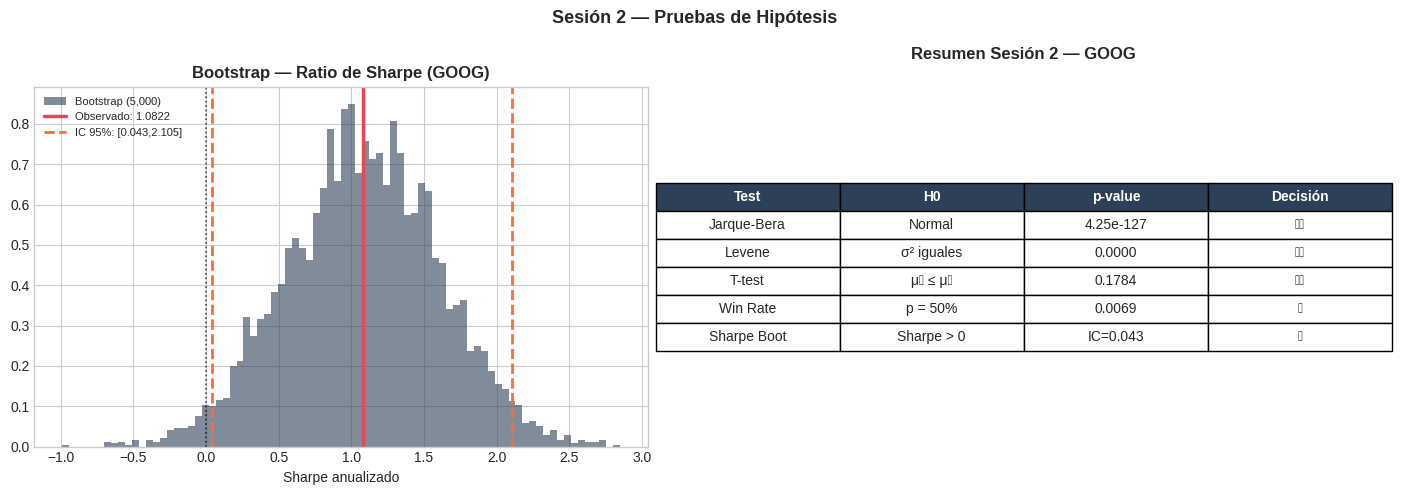


⚠️  TRAMPA DEL P-HACKING:
Si probamos 20 hipótesis con α=5%, esperamos 1 falso positivo por azar.
Solución: validación fuera de muestra (Sesión 5) y corrección de Bonferroni.


In [ ]:
# ── Visualización Sesión 2 ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bootstrap Sharpe
ax = axes[0]
ax.hist(boots, bins=80, density=True, color=COLORES['activo'], alpha=0.6,
        label=f'Bootstrap ({N_BOOTSTRAP:,})')
ax.axvline(sharpe_obs, color=COLORES['mercado'], lw=2.5, label=f'Observado: {sharpe_obs:.4f}')
ax.axvline(ic_boot[0], color=COLORES['var'], lw=2, linestyle='--',
           label=f'IC {int(NIVEL_CONFIANZA*100)}%: [{ic_boot[0]:.3f},{ic_boot[1]:.3f}]')
ax.axvline(ic_boot[1], color=COLORES['var'], lw=2, linestyle='--')
ax.axvline(0, color='black', lw=1.2, linestyle=':', alpha=0.7)
ax.set_title(f'Bootstrap — Ratio de Sharpe ({TICKER_ACTIVO})', fontweight='bold')
ax.set_xlabel('Sharpe anualizado'); ax.legend(fontsize=8)

# Resumen de tests
ax = axes[1]
ax.axis('off')
resumen = [
    ['Test', 'H0', 'p-value', 'Decisión'],
    ['Jarque-Bera',   'Normal',       f"{s2_jb[TICKER_ACTIVO]['pval']:.2e}", '⚠️' if s2_jb[TICKER_ACTIVO]['rechaza'] else '✅'],
    ['Levene',        'σ² iguales',   f'{lev_p:.4f}',  '⚠️' if usar_welch else '✅'],
    ['T-test',        'μ₁ ≤ μ₂',      f'{t_p_uni:.4f}','✅' if rechaza_t else '⚠️'],
    ['Win Rate',      'p = 50%',      f'{p_wr:.4f}',   '✅' if p_wr < ALPHA_STAT else '⚠️'],
    ['Sharpe Boot',   'Sharpe > 0',   f'IC={ic_boot[0]:.3f}', '✅' if ic_boot[0]>0 else '⚠️'],
]
tabla = ax.table(cellText=resumen[1:], colLabels=resumen[0],
                 cellLoc='center', loc='center',
                 colColours=[COLORES['activo']]*4)
tabla.auto_set_font_size(False); tabla.set_fontsize(10); tabla.scale(1.2, 1.8)
for (r,c), cell in tabla.get_celld().items():
    if r == 0: cell.set_text_props(color='white', fontweight='bold')
ax.set_title(f'Resumen Sesión 2 — {TICKER_ACTIVO}', fontweight='bold', pad=20)

plt.suptitle(f'Sesión 2 — Pruebas de Hipótesis', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('sesion2.png', dpi=130, bbox_inches='tight')
plt.show()

print("\n⚠️  TRAMPA DEL P-HACKING:")
print("Si probamos 20 hipótesis con α=5%, esperamos 1 falso positivo por azar.")
print("Solución: validación fuera de muestra (Sesión 5) y corrección de Bonferroni.")


In [ ]:
# Expansión de Corner Fisher:
import numpy as np
import pandas as pd
from scipy import stats

# 1. Extraer serie de retornos limpia
serie_activo = retornos['activo'].dropna()

# 2. Momentos muestrales
mu = serie_activo.mean()
sigma = serie_activo.std()
skew = stats.skew(serie_activo)
kurt_excess = stats.kurtosis(serie_activo, fisher=True) # Exceso de curtosis (K - 3)

# 3. Función para calcular el cuantil ajustado de Cornish-Fisher
def cuantil_cornish_fisher(alpha, S, e):
    z = stats.norm.ppf(alpha)  # Cuantil normal (e.g., -1.645 para alpha=5%)
    z_cf = (z +
            (1/6) * (z**2 - 1) * S +
            (1/24) * (z**3 - 3*z) * e -
            (1/36) * (2*z**3 - 5*z) * (S**2))
    return z_cf

# 4. Comparación de VaR al 95% y 99% (diario y expresado como pérdida positiva)
niveles = [0.05, 0.01]
resultados_var = []

for alpha in niveles:
    confianza = int((1 - alpha) * 100)

    # Cuantiles
    z_norm = stats.norm.ppf(alpha)
    z_cf = cuantil_cornish_fisher(alpha, skew, kurt_excess)

    # Cálculos de VaR
    var_gauss = -(mu + z_norm * sigma)
    var_cf = -(mu + z_cf * sigma)
    var_hist = -np.percentile(serie_activo, alpha * 100)

    resultados_var.append({
        'Nivel de Confianza': f'{confianza}%',
        'VaR Gaussiano (Normal)': f'{var_gauss:.2%}',
        'VaR Cornish-Fisher (Modificado)': f'{var_cf:.2%}',
        'VaR Histórico': f'{var_hist:.2%}',
        'Subestimación Normal vs CF': f'{(var_cf - var_gauss):.2%}'
    })

# Mostrar resultados en tabla
df_var = pd.DataFrame(resultados_var)
print("── COMPARACIÓN DE MODELOS DE VaR (DIARIO) ──")
print(df_var.to_string(index=False))

── COMPARACIÓN DE MODELOS DE VaR (DIARIO) ──
Nivel de Confianza VaR Gaussiano (Normal) VaR Cornish-Fisher (Modificado) VaR Histórico Subestimación Normal vs CF
               95%                  3.03%                           2.85%         2.74%                     -0.18%
               99%                  4.34%                           6.06%         4.72%                      1.72%


---
## Sesión 3 — Regresión Lineal (OLS)

**Conceptos:** Modelo CAPM · β̂=(X'X)⁻¹X'y · Alpha · Beta · R² · Test F


In [ ]:
# ── Preparación de variables ───────────────────────────────────────────────────
# y: exceso de retorno del activo  (r_i - r_f)
# X: constante (alpha) + exceso del mercado (r_m - r_f)
# sm.add_constant() agrega la columna de 1s para estimar el intercepto
y_train = train['exceso_activo']
X_train = sm.add_constant(train['exceso_mercado'])
X_train.columns = ['alpha', 'beta_mercado']

y_test  = test['exceso_activo']
X_test  = sm.add_constant(test['exceso_mercado'])
X_test.columns  = ['alpha', 'beta_mercado']

# ── Estimación OLS ─────────────────────────────────────────────────────────────
# β̂ = (X'X)^{-1} X'y  minimiza la suma de cuadrados de los residuos Σ(y - ŷ)²
# statsmodels lo implementa internamente con descomposición QR (numéricamente estable)
modelo = sm.OLS(y_train, X_train).fit()
print(modelo.summary())


                            OLS Regression Results                            
Dep. Variable:          exceso_activo   R-squared:                       0.350
Model:                            OLS   Adj. R-squared:                  0.349
Method:                 Least Squares   F-statistic:                     387.8
Date:                Tue, 18 Aug 2026   Prob (F-statistic):           2.08e-69
Time:                        23:24:58   Log-Likelihood:                 1997.2
No. Observations:                 723   AIC:                            -3990.
Df Residuals:                     721   BIC:                            -3981.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
alpha            0.0007      0.001      1.285   

In [ ]:
# ── Interpretación detallada ───────────────────────────────────────────────────
alpha_est  = modelo.params['alpha']
beta_est   = modelo.params['beta_mercado']
alpha_pval = modelo.pvalues['alpha']
beta_pval  = modelo.pvalues['beta_mercado']
r2         = modelo.rsquared
r2_adj     = modelo.rsquared_adj
ic_coefs   = modelo.conf_int(alpha=1 - NIVEL_CONFIANZA)

print("INTERPRETACIÓN DEL MODELO CAPM")
print("═"*60)
print(f"\n  α (Alpha) — Retorno Anormal")
print(f"  Estimado: {alpha_est:.7f}  ({alpha_est*DIAS_ANIO:.2%} anual)")
print(f"  IC {int(NIVEL_CONFIANZA*100)}%:  [{ic_coefs.loc['alpha',0]:.7f}, {ic_coefs.loc['alpha',1]:.7f}]")
print(f"  p-value (H0: α=0): {alpha_pval:.6f}  → {'Significativo ✅' if alpha_pval < ALPHA_STAT else 'No significativo ⚠️'}")
if alpha_pval >= ALPHA_STAT:
    print(f"  → No hay evidencia de retorno anormal. El CAPM se sostiene.")
elif alpha_est > 0:
    print(f"  → Alpha positivo: el activo genera valor por encima del riesgo asumido.")
else:
    print(f"  → Alpha negativo: el activo destruye valor ajustado por riesgo.")

print(f"\n  β (Beta) — Sensibilidad al Mercado")
print(f"  Estimado: {beta_est:.4f}  (IC: [{ic_coefs.loc['beta_mercado',0]:.4f}, {ic_coefs.loc['beta_mercado',1]:.4f}])")
print(f"  Por cada 1% del mercado, {TICKER_ACTIVO} se mueve {beta_est:.2f}%.")
perfil = '📈 Agresivo (β>1)' if beta_est>1.2 else ('🛡️  Defensivo (β<1)' if beta_est<0.8 else '⚖️  Neutro (β≈1)')
print(f"  Perfil: {perfil}")

print(f"\n  BONDAD DE AJUSTE")
print(f"  R² = {r2:.4f}  → {r2*100:.1f}% del riesgo del activo explicado por el mercado")
print(f"  R² ajustado = {r2_adj:.4f}  (penaliza variables innecesarias)")
print(f"  F = {modelo.fvalue:.2f}, p = {modelo.f_pvalue:.2e}  → {'Modelo significativo ' if modelo.f_pvalue < ALPHA_STAT else ''}")

# ── Guardar residuos para Sesión 4 ─────────────────────────────────────────────
# En Colab no usamos .pkl — guardamos directamente en variables de Python
# El runtime de Colab mantiene las variables mientras la sesión esté activa
residuos    = modelo.resid
fitted_vals = modelo.fittedvalues
print("\nModelo guardado en variables: 'modelo', 'residuos', 'fitted_vals'")



INTERPRETACIÓN DEL MODELO CAPM
════════════════════════════════════════════════════════════

  α (Alpha) — Retorno Anormal
  Estimado: 0.0007327  (18.46% anual)
  IC 95%:  [-0.0003868, 0.0018522]
  p-value (H0: α=0): 0.199212  → No significativo ⚠️
  → No hay evidencia de retorno anormal. El CAPM se sostiene.

  β (Beta) — Sensibilidad al Mercado
  Estimado: 1.1535  (IC: [1.0385, 1.2685])
  Por cada 1% del mercado, GOOG se mueve 1.15%.
  Perfil: ⚖️  Neutro (β≈1)

  BONDAD DE AJUSTE
  R² = 0.3497  → 35.0% del riesgo del activo explicado por el mercado
  R² ajustado = 0.3488  (penaliza variables innecesarias)
  F = 387.78, p = 2.08e-69  → Modelo significativo 

Modelo guardado en variables: 'modelo', 'residuos', 'fitted_vals'


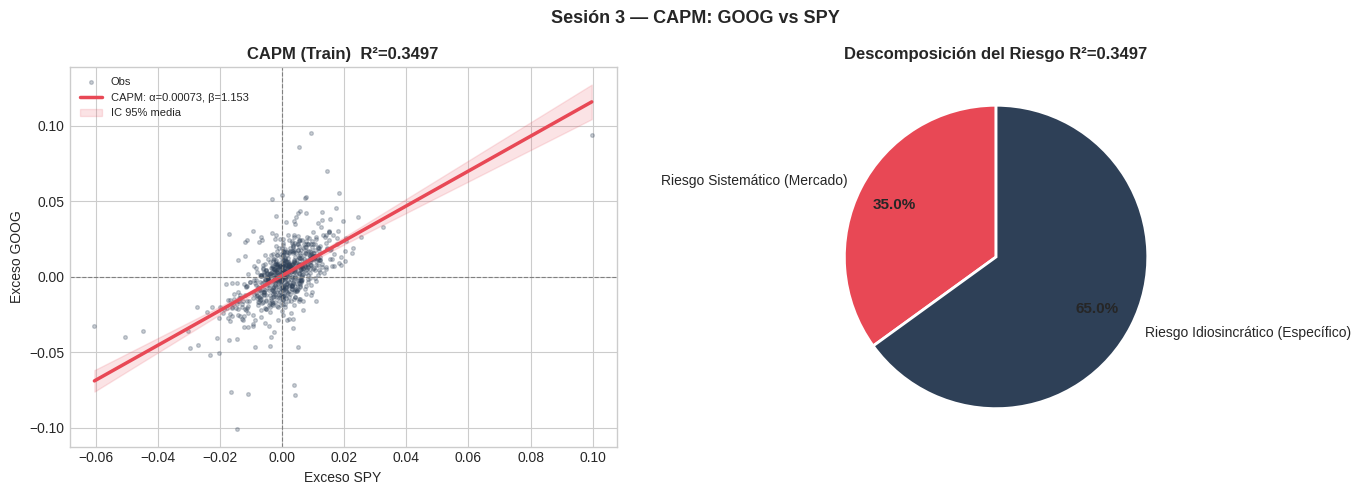

In [ ]:
# ── Visualización Sesión 3 ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter + línea de regresión
ax = axes[0]
x_d = train['exceso_mercado']; y_d = train['exceso_activo']
ax.scatter(x_d, y_d, alpha=0.25, s=7, color=COLORES['activo'], label='Obs')
x_l = np.linspace(x_d.min(), x_d.max(), 300)
y_l = alpha_est + beta_est * x_l
ax.plot(x_l, y_l, color=COLORES['mercado'], lw=2.5,
        label=f'CAPM: α={alpha_est:.5f}, β={beta_est:.3f}')
X_l  = sm.add_constant(pd.Series(x_l, name='exceso_mercado'))
X_l.columns = ['alpha','beta_mercado']
ci   = modelo.get_prediction(X_l).summary_frame(alpha=1-NIVEL_CONFIANZA)
ax.fill_between(x_l, ci['mean_ci_lower'], ci['mean_ci_upper'],
                color=COLORES['mercado'], alpha=0.15,
                label=f'IC {int(NIVEL_CONFIANZA*100)}% media')
ax.axhline(0, color='grey', lw=0.8, linestyle='--')
ax.axvline(0, color='grey', lw=0.8, linestyle='--')
ax.set_xlabel(f'Exceso {TICKER_MERCADO}'); ax.set_ylabel(f'Exceso {TICKER_ACTIVO}')
ax.set_title(f'CAPM (Train)  R²={r2:.4f}', fontweight='bold'); ax.legend(fontsize=8)

# Descomposición del riesgo
ax = axes[1]
wedges, _, autotexts = ax.pie(
    [r2*100, (1-r2)*100],
    labels=['Riesgo Sistemático (Mercado)', 'Riesgo Idiosincrático (Específico)'],
    autopct='%1.1f%%', colors=[COLORES['mercado'], COLORES['activo']],
    startangle=90, pctdistance=0.75,
    wedgeprops={'linewidth': 2, 'edgecolor': 'white'}
)
for at in autotexts: at.set_fontsize(11); at.set_fontweight('bold')
ax.set_title(f'Descomposición del Riesgo R²={r2:.4f}', fontweight='bold')

plt.suptitle(f'Sesión 3 — CAPM: {TICKER_ACTIVO} vs {TICKER_MERCADO}',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('sesion3.png', dpi=130, bbox_inches='tight')
plt.show()


---
## Sesión 4 — Supuestos del Modelo de Regresión Lineal

**Conceptos:** Gauss-Markov · Heterocedasticidad · Autocorrelación · Multicolinealidad · Especificación · Errores robustos HC3/HAC


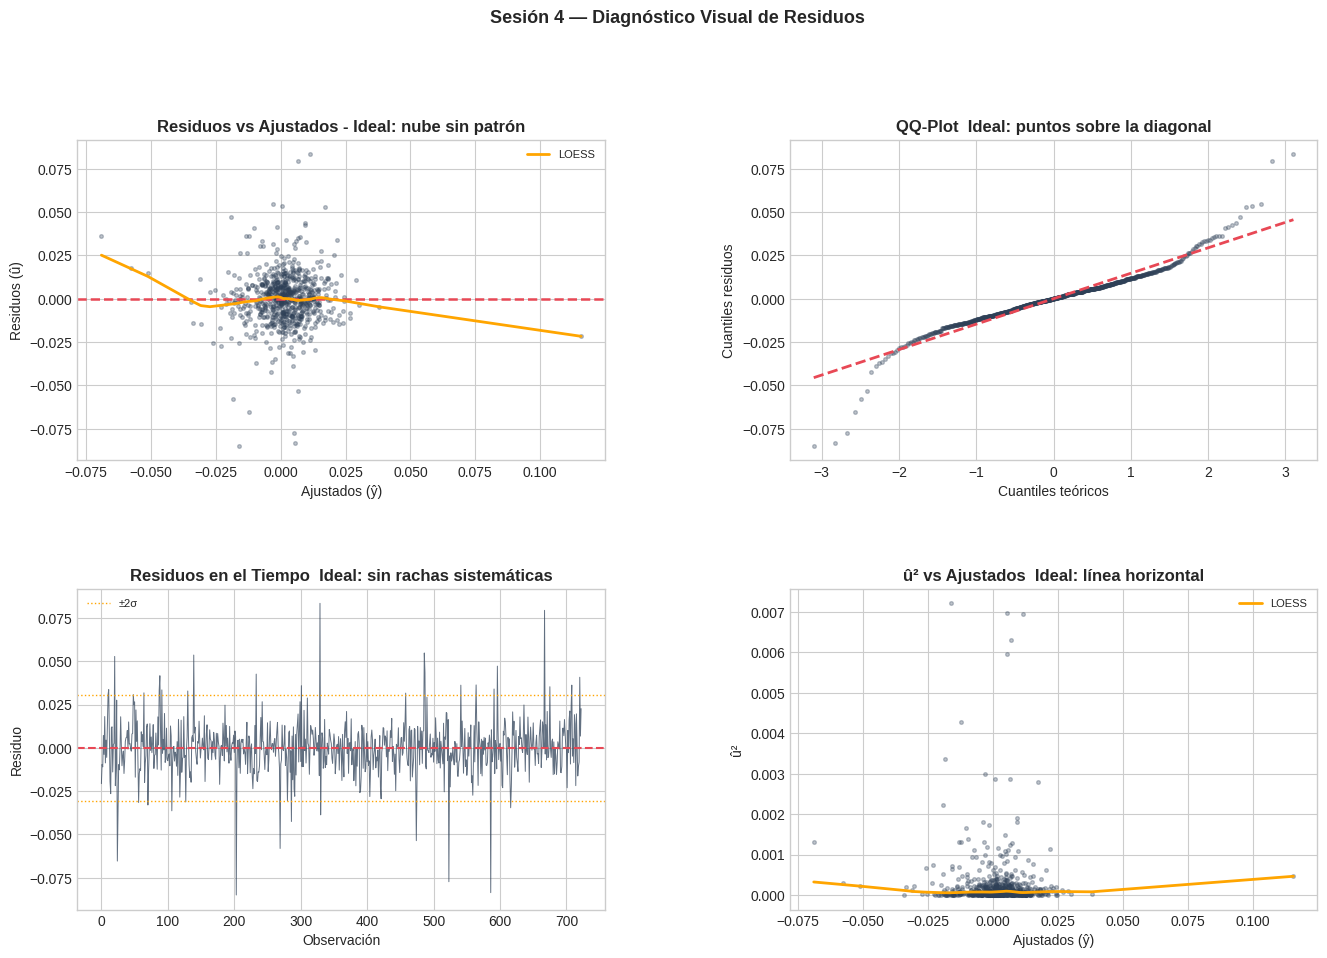

In [ ]:
# ── Panel visual de diagnóstico ────────────────────────────────────────────────
# Los gráficos son el primer paso; los tests formales confirman lo que sugieren

fig = plt.figure(figsize=(16, 10))
gs  = gridspec.GridSpec(2, 2, hspace=0.4, wspace=0.35)

# 1. Residuos vs. Ajustados — detecta heterocedasticidad y no-linealidad
# Buscar: nube aleatoria  | patrón de embudo  | curva
ax = fig.add_subplot(gs[0, 0])
ax.scatter(fitted_vals, residuos, alpha=0.3, s=7, color=COLORES['activo'])
ax.axhline(0, color=COLORES['mercado'], lw=1.8, linestyle='--')
sm_fit = lowess(residuos, fitted_vals, frac=0.3)
ax.plot(sm_fit[:,0], sm_fit[:,1], color='orange', lw=2, label='LOESS')
ax.set_xlabel('Ajustados (ŷ)'); ax.set_ylabel('Residuos (û)')
ax.set_title('Residuos vs Ajustados - Ideal: nube sin patrón', fontweight='bold')
ax.legend(fontsize=8)

# 2. QQ-Plot — detecta no-normalidad
# Buscar: puntos sobre diagonal  | colas separadas  (kurtosis) | S-shape  (asimetría)
ax = fig.add_subplot(gs[0, 1])
(osm, osr), (slope, intercept, _) = stats.probplot(residuos, dist='norm')
ax.scatter(osm, osr, alpha=0.3, s=7, color=COLORES['activo'])
ax.plot(osm, slope*np.array(osm)+intercept, color=COLORES['mercado'], lw=2, linestyle='--')
ax.set_xlabel('Cuantiles teóricos'); ax.set_ylabel('Cuantiles residuos')
ax.set_title('QQ-Plot  Ideal: puntos sobre la diagonal', fontweight='bold')

# 3. Residuos en el tiempo — detecta autocorrelación
# Buscar: sin rachas  | rachas largas  (autocorr. positiva)
ax = fig.add_subplot(gs[1, 0])
ax.plot(residuos.values, color=COLORES['activo'], lw=0.7, alpha=0.75)
ax.axhline(0, color=COLORES['mercado'], lw=1.5, linestyle='--')
std_r = residuos.std()
ax.axhline( 2*std_r, color='orange', lw=1, linestyle=':', label='±2σ')
ax.axhline(-2*std_r, color='orange', lw=1, linestyle=':')
ax.set_xlabel('Observación'); ax.set_ylabel('Residuo')
ax.set_title('Residuos en el Tiempo  Ideal: sin rachas sistemáticas', fontweight='bold')
ax.legend(fontsize=8)

# 4. Residuos² vs Ajustados — visualiza heterocedasticidad directamente
ax = fig.add_subplot(gs[1, 1])
ax.scatter(fitted_vals, residuos**2, alpha=0.3, s=7, color=COLORES['activo'])
sm2 = lowess(residuos**2, fitted_vals, frac=0.3)
ax.plot(sm2[:,0], sm2[:,1], color='orange', lw=2, label='LOESS')
ax.set_xlabel('Ajustados (ŷ)'); ax.set_ylabel('û²')
ax.set_title('û² vs Ajustados  Ideal: línea horizontal', fontweight='bold')
ax.legend(fontsize=8)

plt.suptitle('Sesión 4 — Diagnóstico Visual de Residuos',
             fontsize=13, fontweight='bold', y=1.01)
plt.savefig('sesion4_visual.png', dpi=130, bbox_inches='tight')
plt.show()


In [ ]:
# ── Tests formales de supuestos ────────────────────────────────────────────────
print("DIAGNÓSTICO FORMAL — Supuestos Gauss-Markov")
print("═"*65)
print(f"Nivel de significancia: α = {ALPHA_STAT}\n")

s4_resultados = {}

# ── 1. Normalidad de residuos (Jarque-Bera) ────────────────────────────────────
# DISTINTO de Sesión 2: allí testamos los RETORNOS; aquí testamos los RESIDUOS
# Si se viola: los tests t/F pueden ser imprecisos en muestras pequeñas
# (con n grande el TLC mitiga el problema)
jb2_s, jb2_p, jb2_sk, jb2_ku = jarque_bera(residuos)
r1 = jb2_p < ALPHA_STAT
s4_resultados['normalidad'] = dict(pval=jb2_p, rechaza=r1)
print(f"1. NORMALIDAD DE RESIDUOS (Jarque-Bera)")
print(f"   JB={jb2_s:.2f}, p={jb2_p:.6f}  → {' RECHAZA H0' if r1 else ' No rechaza H0'}")
if r1: print(f"   Mitigación: n grande (TLC) o Bootstrap para inferencia.")

# ── 2. Heterocedasticidad (Breusch-Pagan) ─────────────────────────────────────
# H0: Var(ε|X) = σ² constante
# Si se viola: SE(β̂) es inválido → estadísticos t inflados → falsos positivos
# Corrección: errores robustos HC3 (no cambia β̂, corrige SE)
bp_lm, bp_p, bp_f, bp_fp = het_breuschpagan(residuos, X_train)
r2_bp = bp_p < ALPHA_STAT
s4_resultados['heterocedasticidad'] = dict(pval=bp_p, rechaza=r2_bp)
print(f"\n2. HETEROCEDASTICIDAD (Breusch-Pagan)")
print(f"   LM={bp_lm:.4f}, p={bp_p:.6f}  → {' RECHAZA H0' if r2_bp else ' No rechaza H0'}")
if r2_bp:
    mod_hc3 = sm.OLS(y_train, X_train).fit(cov_type='HC3')
    print(f"   Beta OLS:  {modelo.params['beta_mercado']:.4f} ± {modelo.bse['beta_mercado']:.4f}")
    print(f"   Beta HC3:  {mod_hc3.params['beta_mercado']:.4f} ± {mod_hc3.bse['beta_mercado']:.4f}  (corregido)")

# ── 3. Autocorrelación (Durbin-Watson + Ljung-Box) ────────────────────────────
# H0: Cov(εᵢ, εⱼ) = 0 para i≠j
# DW ≈ 2 → sin autocorrelación | <1.5 → positiva | >2.5 → negativa
# Ljung-Box: más potente para lags múltiples
dw_val = durbin_watson(residuos)
lb = acorr_ljungbox(residuos, lags=[10], return_df=True)
lb_p = lb['lb_pvalue'].values[0]
r3 = lb_p < ALPHA_STAT
s4_resultados['autocorrelacion'] = dict(dw=dw_val, lb_pval=lb_p, rechaza=r3)
dw_int = ' autocorr. positiva' if dw_val<1.5 else (' autocorr. negativa' if dw_val>2.5 else ' sin autocorr.')
print(f"\n3. AUTOCORRELACIÓN")
print(f"   Durbin-Watson: {dw_val:.4f}  ({dw_int})")
print(f"   Ljung-Box (10 lags): p={lb_p:.6f}  → {' RECHAZA H0' if r3 else ' No rechaza H0'}")
if r3:
    mod_hac = sm.OLS(y_train, X_train).fit(cov_type='HAC', cov_kwds={'maxlags': 5})
    print(f"   Beta OLS: {modelo.params['beta_mercado']:.4f} ± {modelo.bse['beta_mercado']:.4f}")
    print(f"   Beta HAC: {mod_hac.params['beta_mercado']:.4f} ± {mod_hac.bse['beta_mercado']:.4f}  (Newey-West)")

# ── 4. Multicolinealidad (VIF) ────────────────────────────────────────────────
# VIF = 1/(1-R²_j)  donde R²_j regresa x_j sobre los demás regresores
# VIF=1 en CAPM simple (1 variable); relevante en modelos multifactoriales
print(f"\n4. MULTICOLINEALIDAD (VIF)")
for i, col in enumerate(X_train.columns):
    if col == 'alpha': continue
    vif = variance_inflation_factor(X_train.values, i)
    nivel = ' OK' if vif < 5 else ('⚡ Moderada' if vif < 10 else ' SEVERA')
    print(f"   VIF({col}) = {vif:.4f}  → {nivel}")
    print(f"   (VIF=1 en CAPM simple; >10 sería problema en Fama-French)")
s4_resultados['multicolinealidad'] = dict(rechaza=False)

# ── 5. Especificación (RESET de Ramsey) ──────────────────────────────────────
# H0: la forma funcional lineal es correcta
# Si rechaza: podría faltar una variable o la relación no es lineal
# → Considerar Fama-French (SMB, HML) o términos cuadráticos
reset_r = linear_reset(modelo, use_f=True)
r5 = reset_r.pvalue < ALPHA_STAT
s4_resultados['especificacion'] = dict(pval=reset_r.pvalue, rechaza=r5)
print(f"\n5. ESPECIFICACIÓN (RESET de Ramsey)")
print(f"   F={reset_r.statistic:.4f}, p={reset_r.pvalue:.6f}  → {' RECHAZA H0' if r5 else ' No rechaza H0'}")
if r5: print(f"   Sugerencia: agregar factores adicionales (Fama-French SMB, HML).")

# ── Resumen ────────────────────────────────────────────────────────────────────
print(f"\n{'═'*65}")
print("  RESUMEN")
items = [('Normalidad residuos','normalidad'),('Homocedasticidad','heterocedasticidad'),
         ('No autocorrelación','autocorrelacion'),('Especificación','especificacion')]
for nombre, key in items:
    v = s4_resultados[key]['rechaza']
    p = s4_resultados[key].get('pval', s4_resultados[key].get('lb_pval','—'))
    pstr = f'p={p:.4f}' if isinstance(p, float) else str(p)
    print(f"  {'  VIOLADO' if v else ' OK     '}  {nombre:<28} {pstr}")

# Modelo final recomendado
hac_viol = s4_resultados['autocorrelacion']['rechaza']
hc_viol  = s4_resultados['heterocedasticidad']['rechaza']
if hac_viol:
    modelo_final = sm.OLS(y_train, X_train).fit(cov_type='HAC', cov_kwds={'maxlags':5})
    print("\n  → Modelo final: errores HAC (Newey-West)")
elif hc_viol:
    modelo_final = sm.OLS(y_train, X_train).fit(cov_type='HC3')
    print("\n  → Modelo final: errores HC3")
else:
    modelo_final = modelo
    print("\n  → Modelo final: OLS estándar (todos los supuestos clave OK)")


DIAGNÓSTICO FORMAL — Supuestos Gauss-Markov
═════════════════════════════════════════════════════════════════
Nivel de significancia: α = 0.05

1. NORMALIDAD DE RESIDUOS (Jarque-Bera)
   JB=1175.64, p=0.000000  →  RECHAZA H0
   Mitigación: n grande (TLC) o Bootstrap para inferencia.

2. HETEROCEDASTICIDAD (Breusch-Pagan)
   LM=1.1228, p=0.289316  →  No rechaza H0

3. AUTOCORRELACIÓN
   Durbin-Watson: 1.8898  ( sin autocorr.)
   Ljung-Box (10 lags): p=0.497651  →  No rechaza H0

4. MULTICOLINEALIDAD (VIF)
   VIF(beta_mercado) = 1.0000  →  OK
   (VIF=1 en CAPM simple; >10 sería problema en Fama-French)

5. ESPECIFICACIÓN (RESET de Ramsey)
   F=4.6683, p=0.009675  →  RECHAZA H0
   Sugerencia: agregar factores adicionales (Fama-French SMB, HML).

═════════════════════════════════════════════════════════════════
  RESUMEN
    VIOLADO  Normalidad residuos          p=0.0000
   OK       Homocedasticidad             p=0.2893
   OK       No autocorrelación           p=0.4977
    VIOLADO  Especif

---
## Sesión 5 — Predicción

**Conceptos:** In-sample vs out-of-sample · MSE · RMSE · MAE · R² OOS · Intervalos de predicción · Alpha realizado


In [ ]:
# ── Predicciones ──────────────────────────────────────────────────────────────
# In-sample:     modelo predice sobre datos que YA conoce (train)
# Out-of-sample: modelo predice sobre datos que NUNCA vio (test)
# La diferencia entre ambos mide la capacidad de generalización del modelo

y_pred_train = modelo_final.predict(X_train)   # ŷ = Xβ̂  (datos conocidos)
y_pred_test  = modelo_final.predict(X_test)    # ŷ = X_test β̂_train (datos nuevos)

def metricas(y_real, y_pred, nombre):
    """
    MSE  = (1/n) Σ(y−ŷ)²    penaliza errores grandes
    RMSE = √MSE              en unidades de retorno; anualizado = RMSE × √252
    MAE  = (1/n) Σ|y−ŷ|     menos sensible a outliers que RMSE
    R²   = 1 − SSE/TSS       puede ser negativo OOS si el modelo es peor que la media
    """
    mse  = mean_squared_error(y_real, y_pred)
    rmse = np.sqrt(mse)
    mae  = mean_absolute_error(y_real, y_pred)
    r2   = r2_score(y_real, y_pred)
    print(f"  {nombre}: RMSE={rmse:.6f} ({rmse*np.sqrt(DIAS_ANIO):.2%} anual) | "
          f"MAE={mae:.6f} | R²={r2:.6f}" + ("  R²<0" if r2 < 0 else ""))
    return dict(mse=mse, rmse=rmse, mae=mae, r2=r2,
                rmse_anual=rmse*np.sqrt(DIAS_ANIO))

print("MÉTRICAS DE ERROR DE PREDICCIÓN")
print("═"*65)
m_tr = metricas(y_train, y_pred_train, f"IN-SAMPLE     (Train {len(y_train)} obs)")
m_te = metricas(y_test,  y_pred_test,  f"OUT-OF-SAMPLE (Test  {len(y_test)} obs)")

deg_r2 = m_tr['r2'] - m_te['r2']
print(f"\n  Degradación R²: {deg_r2:+.4f}  |  Incremento RMSE: {(m_te['rmse']-m_tr['rmse'])/m_tr['rmse']*100:+.1f}%")
if deg_r2 > 0.20:
    print("  ⚠️  Degradación importante: posible overfitting o cambio de régimen.")
elif deg_r2 > 0.05:
    print("    Degradación moderada — normal en modelos financieros.")
else:
    print("    Degradación mínima — el modelo generaliza bien.")


MÉTRICAS DE ERROR DE PREDICCIÓN
═════════════════════════════════════════════════════════════════
  IN-SAMPLE     (Train 723 obs): RMSE=0.015278 (24.25% anual) | MAE=0.010597 | R²=0.349737
  OUT-OF-SAMPLE (Test  181 obs): RMSE=0.017103 (27.15% anual) | MAE=0.011830 | R²=0.313717

  Degradación R²: +0.0360  |  Incremento RMSE: +11.9%
    Degradación mínima — el modelo generaliza bien.


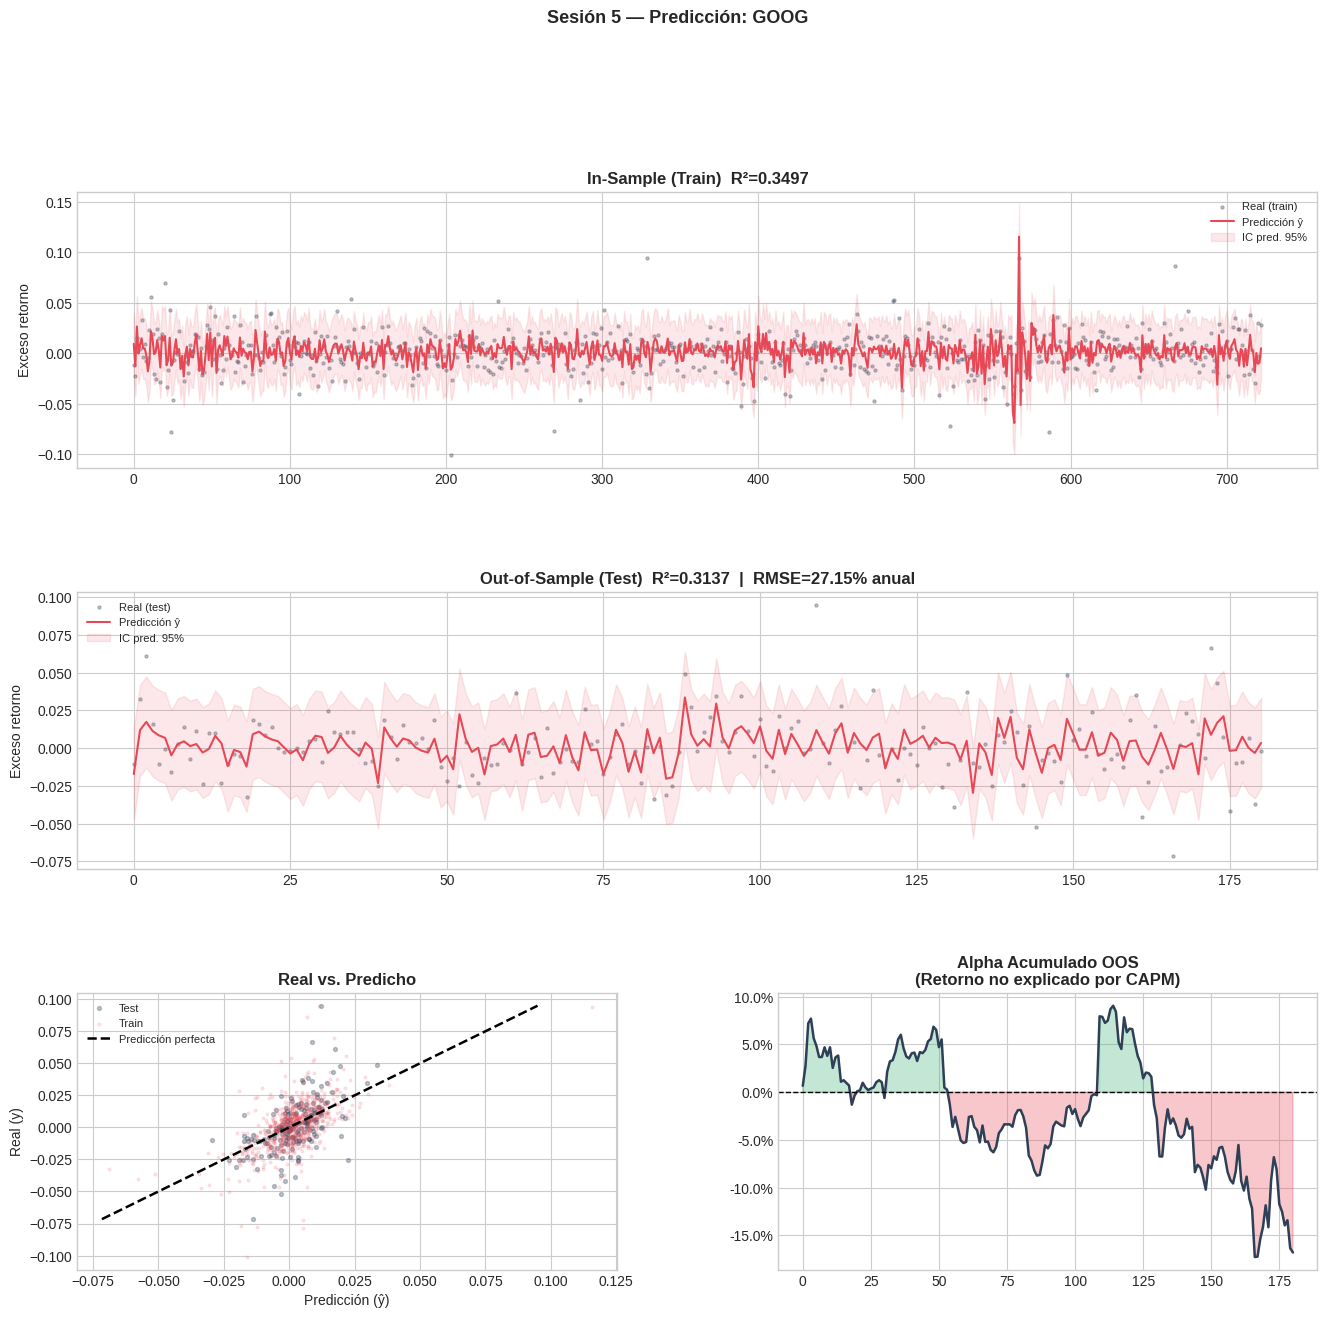

In [ ]:
# ── Visualización Sesión 5 ───────────────────────────────────────────
pred_tr_obj = modelo_final.get_prediction(X_train)
pred_te_obj = modelo_final.get_prediction(X_test)
pred_tr_df  = pred_tr_obj.summary_frame(alpha=1-NIVEL_CONFIANZA)
pred_te_df  = pred_te_obj.summary_frame(alpha=1-NIVEL_CONFIANZA)

fig = plt.figure(figsize=(16, 14))
gs  = gridspec.GridSpec(3, 2, hspace=0.45, wspace=0.3)

# In-sample
ax = fig.add_subplot(gs[0, :])
ax.scatter(range(len(y_train)), y_train.values, alpha=0.3, s=5,
           color=COLORES['activo'], label='Real (train)')
ax.plot(range(len(y_train)), pred_tr_df['mean'].values,
        color=COLORES['mercado'], lw=1.5, label='Predicción ŷ')
ax.fill_between(range(len(y_train)),
                pred_tr_df['obs_ci_lower'].values,
                pred_tr_df['obs_ci_upper'].values,
                color=COLORES['mercado'], alpha=0.12,
                label=f'IC pred. {int(NIVEL_CONFIANZA*100)}%')
ax.set_title(f'In-Sample (Train)  R²={m_tr["r2"]:.4f}', fontweight='bold')
ax.set_ylabel('Exceso retorno'); ax.legend(fontsize=8)

# Out-of-sample
ax = fig.add_subplot(gs[1, :])
ax.scatter(range(len(y_test)), y_test.values, alpha=0.3, s=5,
           color=COLORES['activo'], label='Real (test)')
ax.plot(range(len(y_test)), pred_te_df['mean'].values,
        color=COLORES['mercado'], lw=1.5, label='Predicción ŷ')
ax.fill_between(range(len(y_test)),
                pred_te_df['obs_ci_lower'].values,
                pred_te_df['obs_ci_upper'].values,
                color=COLORES['mercado'], alpha=0.12,
                label=f'IC pred. {int(NIVEL_CONFIANZA*100)}%')
ax.set_title(f'Out-of-Sample (Test)  R²={m_te["r2"]:.4f}  |  RMSE={m_te["rmse_anual"]:.2%} anual',
             fontweight='bold')
ax.set_ylabel('Exceso retorno'); ax.legend(fontsize=8)

# Real vs predicho
ax = fig.add_subplot(gs[2, 0])
lims = [min(y_test.min(), y_pred_test.min()), max(y_test.max(), y_pred_test.max())]
ax.scatter(y_pred_test.values, y_test.values, alpha=0.3, s=8,
           color=COLORES['activo'], label='Test')
ax.scatter(y_pred_train.values, y_train.values, alpha=0.12, s=4,
           color=COLORES['mercado'], label='Train')
ax.plot(lims, lims, 'k--', lw=1.8, label='Predicción perfecta')
ax.set_xlabel('Predicción (ŷ)'); ax.set_ylabel('Real (y)')
ax.set_title('Real vs. Predicho', fontweight='bold'); ax.legend(fontsize=8)

# Alpha acumulado OOS
ax = fig.add_subplot(gs[2, 1])
error_oos  = y_test - y_pred_test
alpha_acum = (1 + error_oos).cumprod() - 1
ax.plot(alpha_acum.values, color=COLORES['activo'], lw=1.8)
ax.axhline(0, color='black', lw=1, linestyle='--')
ax.fill_between(range(len(alpha_acum)), 0, alpha_acum.values,
                where=alpha_acum.values >= 0, color=COLORES['positivo'], alpha=0.3)
ax.fill_between(range(len(alpha_acum)), 0, alpha_acum.values,
                where=alpha_acum.values < 0, color=COLORES['negativo'], alpha=0.3)
ax.set_title(f'Alpha Acumulado OOS\n(Retorno no explicado por CAPM)', fontweight='bold')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f'{x:.1%}'))

plt.suptitle(f'Sesión 5 — Predicción: {TICKER_ACTIVO}', fontsize=13, fontweight='bold', y=1.01)
plt.savefig('sesion5.png', dpi=130, bbox_inches='tight')
plt.show()


In [ ]:
# ── Alpha realizado y test de sesgo ───────────────────────────────────────────
# El error OOS = retorno real − lo que predijo el CAPM
# Es el "alpha realizado": el alpha más honesto porque se calcula en datos NO vistos
error_oos = y_test - y_pred_test
t_bias, p_bias = stats.ttest_1samp(error_oos, 0)

print("ALPHA REALIZADO — Error Out-of-Sample")
print("═"*60)
print(f"  Error medio diario:     {error_oos.mean():.6f}")
print(f"  Alpha realizado anual:  {error_oos.mean()*DIAS_ANIO:.2%}")
print(f"  Test H0: error medio = 0  →  t={t_bias:.4f}, p={p_bias:.6f}")
print(f"  {' Sesgo sistemático — modelo mal especificado' if p_bias < ALPHA_STAT else ' Sin sesgo — predicción insesgada'}")


ALPHA REALIZADO — Error Out-of-Sample
════════════════════════════════════════════════════════════
  Error medio diario:     -0.000870
  Alpha realizado anual:  -21.92%
  Test H0: error medio = 0  →  t=-0.6833, p=0.495313
   Sin sesgo — predicción insesgada


---
## Resumen Integrador


In [ ]:
# ── Resumen completo del pipeline ─────────────────────────────────────────────
print("═"*70)
print(f"  RESUMEN INTEGRADOR — {TICKER_ACTIVO} vs {TICKER_MERCADO}")
print(f"  Período: {FECHA_INICIO} → {FECHA_FIN}")
print("═"*70)
print(f"""\n  SESIÓN 1 — Inferencia Estadística
    Retorno diario:     {s1_activo['media']:.5%}  |  Vol anual: {s1_activo['vol_anual']:.2%}
    Sharpe anual:       {s1_activo['sharpe']:.4f}
    VaR {int(NIVEL_CONFIANZA*100)}% paramétrico:  {s1_activo['var_param']:.3%}/día
    IC {int(NIVEL_CONFIANZA*100)}% media:      [{s1_activo['ic'][0]:.4%}, {s1_activo['ic'][1]:.4%}]
    ¿0 en el IC?        {'Sí ⚠️ — retorno no significativo' if s1_activo['ic'][0] < 0 < s1_activo['ic'][1] else 'No ✅ — retorno significativo'}

  SESIÓN 2 — Pruebas de Hipótesis
    Normalidad (JB):    {'Rechazada ⚠️' if s2_jb[TICKER_ACTIVO]['rechaza'] else 'No rechazada ✅'}
    Igualdad varianzas: {'Rechazada ⚠️ → Welch' if usar_welch else 'No rechazada ✅ → Pooled'}
    Outperformance:     {'Sí ✅' if rechaza_t else 'No ⚠️'}  (p={t_p_uni:.4f})
    Sharpe Bootstrap:   {s2_boot['sharpe_obs']:.4f}  IC=[{s2_boot['ic'][0]:.3f}, {s2_boot['ic'][1]:.3f}]

  SESIÓN 3 — Modelo CAPM (OLS)
    Alpha (α):          {alpha_est:.6f}  ({alpha_est*DIAS_ANIO:.2%} anual)  p={alpha_pval:.4f}
    Beta  (β):          {beta_est:.4f}   ({perfil})
    R²:                 {r2:.4f}  ({r2*100:.1f}% riesgo explicado por el mercado)

  SESIÓN 4 — Supuestos
    Normalidad:         {'⚠️ VIOLADO' if s4_resultados['normalidad']['rechaza'] else '✅ OK'}
    Homocedasticidad:   {'⚠️ VIOLADO' if s4_resultados['heterocedasticidad']['rechaza'] else '✅ OK'}
    No autocorrelación: {'⚠️ VIOLADO' if s4_resultados['autocorrelacion']['rechaza'] else '✅ OK'}
    Especificación:     {'⚠️ VIOLADO' if s4_resultados['especificacion']['rechaza'] else '✅ OK'}

  SESIÓN 5 — Predicción
    RMSE out-of-sample: {m_te['rmse_anual']:.2%} anual
    R² out-of-sample:   {m_te['r2']:.4f}
    Alpha OOS anual:    {error_oos.mean()*DIAS_ANIO:.2%}
    Sesgo sistemático:  {'Sí ⚠️' if p_bias < ALPHA_STAT else 'No ✅'}
""")
print("═"*70)



══════════════════════════════════════════════════════════════════════
  RESUMEN INTEGRADOR — GOOG vs SPY
  Período: 2023-01-01 → 2026-08-13
══════════════════════════════════════════════════════════════════════

  SESIÓN 1 — Inferencia Estadística
    Retorno diario:     0.14914%  |  Vol anual: 30.66%
    Sharpe anual:       1.2259
    VaR 95% paramétrico:  -3.636%/día
    IC 95% media:      [0.0233%, 0.2750%]
    ¿0 en el IC?        No ✅ — retorno significativo

  SESIÓN 2 — Pruebas de Hipótesis
    Normalidad (JB):    Rechazada ⚠️
    Igualdad varianzas: Rechazada ⚠️ → Welch
    Outperformance:     No ⚠️  (p=0.1784)
    Sharpe Bootstrap:   1.0822  IC=[0.043, 2.105]

  SESIÓN 3 — Modelo CAPM (OLS)
    Alpha (α):          0.000733  (18.46% anual)  p=0.1992
    Beta  (β):          1.1535   (⚖️  Neutro (β≈1))
    R²:                 0.3497  (35.0% riesgo explicado por el mercado)

  SESIÓN 4 — Supuestos
    Normalidad:         ⚠️ VIOLADO
    Homocedasticidad:   ✅ OK
    No autocorrelaci